verifica mu positiva: 
True
verifica mu simmetrica: 
True
verifica mu compatibile con B + I_0: 
True


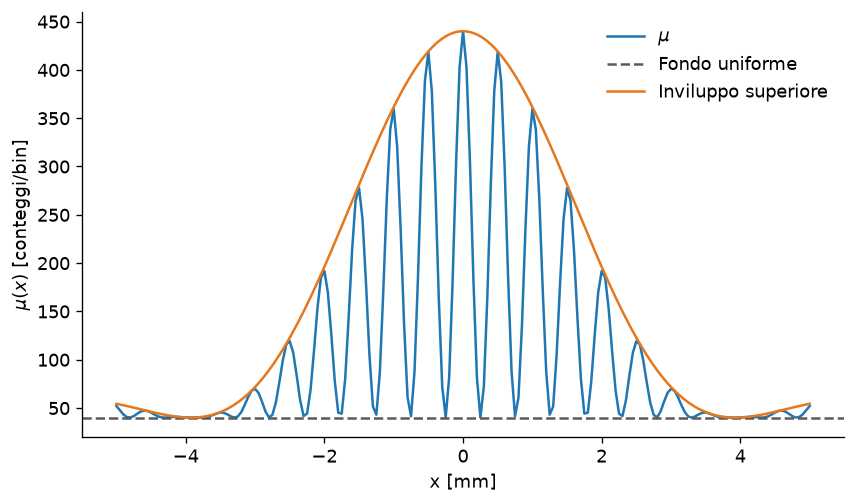

In [53]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import curve_fit

ROSSO = "#C92512"
GRIGIO = "#5A5A5A"
AZZURRO = "#2E6F9E"
ARANCIONE = "#E5771C"
plt.rcParams.update({
    "figure.figsize": (8.2, 4.6),
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.labelsize": 11,
    "axes.titlesize": 12,
    "font.size": 11,
    "legend.frameon": False,
})

B = 40
I_0 = 400
alpha = 0.80
delta = 6.20
x = np.linspace(-5.0, 5.0, 201)

E = np.sinc(alpha*x/np.pi)**2
C = np.cos(delta*x)**2

mu = B + I_0*E*C

#verifica mu positiva, simmetrica, finita
print("verifica mu positiva: ")
print(mu.all()>0) 

print("verifica mu simmetrica: ")
a = False
for i in range(len(mu)): 
    if np.isclose(mu[i], mu[-i-1]):
        a = True
print(a)

#finita (?)

print("verifica mu compatibile con B + I_0: ")
print(mu[len(mu)//2] == B + I_0)

#plotting
fig, ax = plt.subplots()
ax.plot(x, mu, label=r"$\mu$")
ax.axhline(B, color=GRIGIO, ls="--", label="Fondo uniforme")
ax.plot(x, B+I_0*E, color=ARANCIONE, label="Inviluppo superiore")
ax.set(xlabel="x [mm]", ylabel=r"$\mu(x)$ [conteggi/bin]")
ax.legend()
plt.show()
#alpha modifica la larghezza del massimo centrale, delta modifica la distanza tra le frange



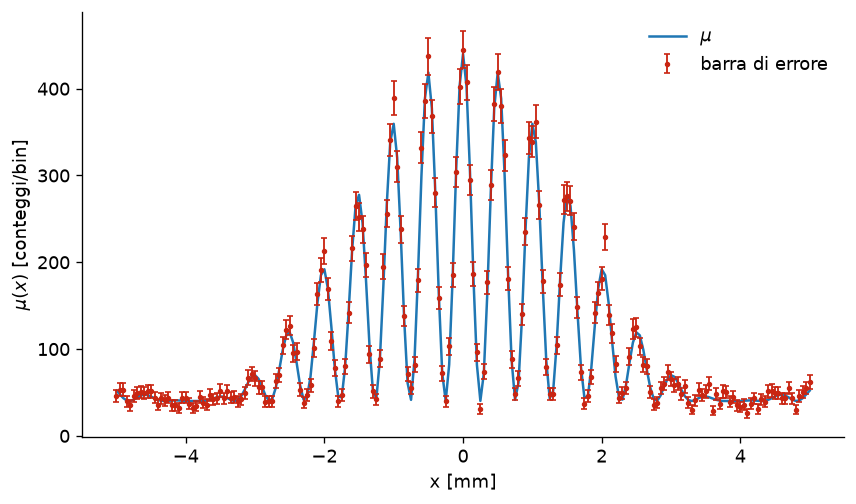

Confronto con la fluttuazione statistica: 
di N_c - mu_c = 205.620, sqrt(mu_c) = 104.668
scarto = 1.964


In [64]:
rng = np.random.default_rng(18676)
n_i = rng.poisson(mu)
sigma_i = np.sqrt(n_i)
for i in range(len(n_i)):
    if np.isclose(n_i[i], 0):
        sigma_i[i]=1

fig, ax = plt.subplots()
ax.plot(x, mu, label=r"$\mu$")
ax.set(xlabel="x [mm]", ylabel=r"$\mu(x)$ [conteggi/bin]")
ax.errorbar(x, n_i,yerr=sigma_i, fmt=".", color=ROSSO, markersize=4.5, capsize=2, elinewidth=1.1, label="barra di errore")
ax.legend()
plt.show()

N_c = np.sum(n_i[abs(x)<1.2])
mu_c = np.sum(mu[abs(x)<1.2])

print("Confronto con la fluttuazione statistica: ") #??
a = N_c - mu_c

print(f"di N_c - mu_c = {a:.3f}, sqrt(mu_c) = {np.sqrt(mu_c):.3f}")

scarto= abs(a)/np.sqrt(mu_c) #??
print(f"scarto = {scarto:.3f}")

In [ ]:
M = 2000
def esperimento(mu, x, rng):
    n_i,j = rng.poisson(mu)
    N_c,j = np.sum(n_i,j[abs(x)<1.2])
    return N_c,j
esperimenti = np.array([esperimento(mu, x, rng) for i in range(M)])
media_esperimenti = esperimenti.mean()
sigma_esperimenti = esperimenti.std(ddof=1)

